# Navier–Stokes in SymPy for a Delivery Drone

This notebook follows on from [`delivery_robot_vs_driver.ipynb`](delivery_robot_vs_driver.ipynb)
and adds a third courier: a **quadcopter**. Its physics is fluid mechanics.

| Part | What | Tool |
|---|---|---|
| 1 | The incompressible Navier–Stokes equations, and why only $Re$ matters | SymPy |
| 2 | Four exact solutions, each checked by substituting it back in | SymPy |
| 3 | Boundary layers on a drone arm (Blasius) | SciPy shooting |
| 4 | Rotor thrust and power from momentum theory | SymPy, then numbers |
| 5 | Drone vs. robot vs. car: energy per mile | numbers |
| 6 | **Auditing an AI flow prediction**: low data error doesn't mean it obeys the physics | least squares |
| 7 | **Applied EM**: fiber dispersion (Jalali time-stretch) is diffusion with an *imaginary* viscosity | SymPy |

Everything goes through [`dgs/uav_navier_stokes.py`](../dgs/uav_navier_stokes.py).
Drone masses, rotor sizes, and drag areas are assumed round numbers.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))

import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from IPython.display import display, Math

from dgs.uav_navier_stokes import (
    x, y, t, nu, rho, mu,
    ns_residuals, nondimensional_ns, reynolds,
    couette, plane_poiseuille, stokes_first_problem, taylor_green, blasius,
    actuator_disk_derivation, hover_power, forward_flight_power, energy_per_mile_wh,
    fit_surrogate, taylor_green_numeric, diffusion_gaussian, dispersed_pulse, check_analogy,
)
sp.init_printing()

# Part 1: The equations, and why only $Re$ matters

Assume incompressible flow with constant $\rho, \mu$ and $\nu=\mu/\rho$:

$$\nabla\cdot\vec u = 0,\qquad
\underbrace{\partial_t\vec u + (\vec u\cdot\nabla)\vec u}_{\text{acceleration of a fluid parcel}}
= -\frac{1}{\rho}\nabla p + \nu\nabla^2\vec u$$

`ns_residuals(u, v, p)` moves everything to one side and returns
(continuity, $x$-momentum, $y$-momentum). A field is an exact solution **if and
only if** all three residuals are identically zero.

**Nondimensionalization.** Substitute $x = Lx^\*$, $u = Uu^\*$, $t = (L/U)t^\*$,
$p = \rho U^2 p^\*$, then divide by $U^2/L$. Every dimensional constant
collapses into one number:

In [2]:
expr, Re = nondimensional_ns()
display(Math(r"\text{x-momentum}/(U^2/L) = " + sp.latex(expr)))
print("free symbols:", expr.free_symbols)

<IPython.core.display.Math object>

free symbols: {y_s, x_s, Re, t_s}


Only $Re = UL/\nu$ is left. So a drone and a scale model in a wind tunnel behave
the same if their $Re$ match. Typical values for a delivery drone, with
$\nu_\text{air} = 1.5\times10^{-5}$ m²/s:

In [3]:
cases = [
    ("rotor blade tip (chord 3 cm, 100 m/s)", 100, 0.03),
    ("drone arm (2 cm tube, 15 m/s)",          15, 0.02),
    ("drone body (30 cm, 15 m/s)",            15, 0.30),
    ("sidewalk robot (70 cm, 1.6 m/s)",       1.56, 0.70),
    ("car (4.5 m, 11 m/s)",                   11.2, 4.5),
]
for name, U, L in cases:
    print(f"{name:42s} Re = {reynolds(U, L):10.3g}")

rotor blade tip (chord 3 cm, 100 m/s)      Re =      2e+05
drone arm (2 cm tube, 15 m/s)              Re =      2e+04
drone body (30 cm, 15 m/s)                 Re =      3e+05
sidewalk robot (70 cm, 1.6 m/s)            Re =   7.28e+04
car (4.5 m, 11 m/s)                        Re =   3.36e+06


All of these are $\gg 1$, so inertia dominates and the viscous term matters only in
thin **boundary layers** near surfaces (Part 3). The rotor blade, at
$Re\sim10^5$, sits in an awkward transitional range. That's one reason small-drone
propellers are less efficient than helicopter rotors.

# Part 2: Exact solutions, verified by substitution

The nonlinear term $(\vec u\cdot\nabla)\vec u$ is why Navier–Stokes is hard. Each
solution below gets around it in a different way:

| solution | how the nonlinear term disappears |
|---|---|
| Couette (sliding plate) | $u=u(y)$ only, so $u\,\partial_x u = 0$ |
| plane Poiseuille (pressure-driven channel) | same, with a constant $\partial_x p$ |
| Stokes' first problem (plate suddenly set moving) | $u(y,t)$ only. The equation reduces to the **diffusion equation** $u_t = \nu u_{yy}$ |
| Taylor–Green vortex | the nonlinear term is *nonzero*, but it equals a pure pressure gradient, so the pressure absorbs it |

In [4]:
for name, f in (("Couette", couette), ("plane Poiseuille", plane_poiseuille),
                ("Stokes 1st problem", stokes_first_problem), ("Taylor-Green", taylor_green)):
    u, v, p = f()
    print(f"{name:20s} u = {str(u):45s} residuals = {ns_residuals(u, v, p)}")

# Show the Taylor-Green nonlinear term is NOT zero -- it's balanced by pressure
u, v, p = taylor_green()
conv_x = sp.simplify(u*sp.diff(u, x) + v*sp.diff(u, y))
print("\nTaylor-Green (u·∇)u_x =", conv_x, "   -p_x/rho =", sp.simplify(-sp.diff(p, x)/rho))

Couette              u = U*y/h                                         residuals = (0, 0, 0)
plane Poiseuille     u = G*(h**2 - y**2)/(2*nu*rho)                    residuals = (0, 0, 0)
Stokes 1st problem   u = U*erfc(y/(2*sqrt(nu)*sqrt(t)))                residuals = (0, 0, 0)
Taylor-Green         u = exp(-2*nu*t)*sin(x)*cos(y)                    residuals = (0, 0, 0)

Taylor-Green (u·∇)u_x = exp(-4*nu*t)*sin(2*x)/2    -p_x/rho = exp(-4*nu*t)*sin(2*x)/2


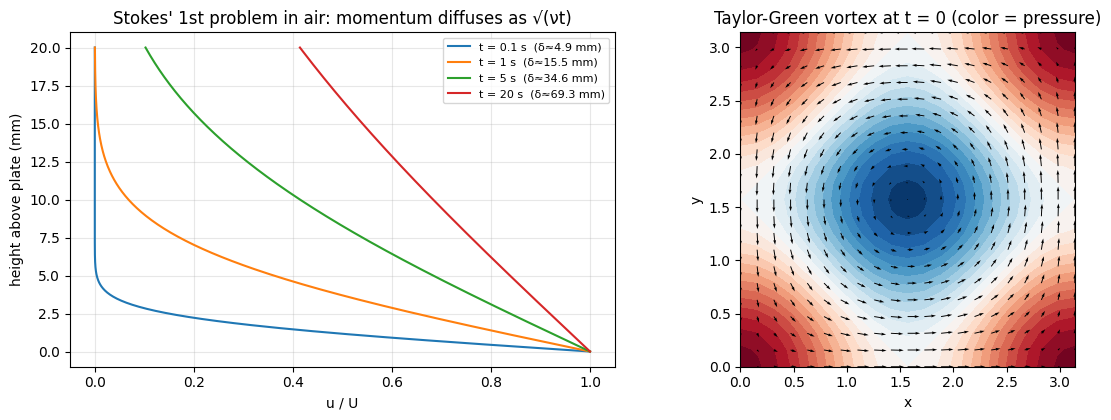

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
U0, nu0 = 1.0, 1.5e-5
f_stokes = sp.lambdify((y, t), stokes_first_problem(U=U0)[0].subs(nu, nu0), ["scipy", "numpy"])
yy = np.linspace(0, 0.02, 300)
for tt in (0.1, 1, 5, 20):
    axes[0].plot(f_stokes(yy, tt), 1000*yy, label=f"t = {tt} s  (δ≈{1000*4*np.sqrt(nu0*tt):.1f} mm)")
axes[0].set(xlabel="u / U", ylabel="height above plate (mm)",
            title="Stokes' 1st problem in air: momentum diffuses as √(νt)")
axes[0].legend(fontsize=8); axes[0].grid(alpha=0.3)

g = np.linspace(0, np.pi, 21); X, Y = np.meshgrid(g, g)
uu, vv, pp = taylor_green_numeric(X, Y, 0.0)
axes[1].contourf(X, Y, pp, 30, cmap="RdBu_r")
axes[1].quiver(X, Y, uu, vv)
axes[1].set(title="Taylor-Green vortex at t = 0 (color = pressure)", xlabel="x", ylabel="y", aspect="equal")
plt.tight_layout(); plt.show()

# Part 3: The boundary layer on a drone arm (Blasius)

Along a flat surface, Prandtl's boundary-layer scaling turns Navier–Stokes into a
similarity ODE. With $\eta = y\sqrt{U/(\nu x)}$ and $u/U = f'(\eta)$:

$$f''' + \tfrac12 f f'' = 0,\qquad f(0)=f'(0)=0,\; f'(\infty)=1$$

The unknown is $f''(0)$. Guess it, integrate, see whether $f'$ reaches 1, and
adjust (**shooting**, with `brentq`). The textbook values are
$f''(0) = 0.33206$ and $\delta_{99} = 4.91\,x/\sqrt{Re_x}$.

f''(0)  = 0.332057   (textbook 0.332057)
δ99 η   = 4.9100     (textbook 4.91)


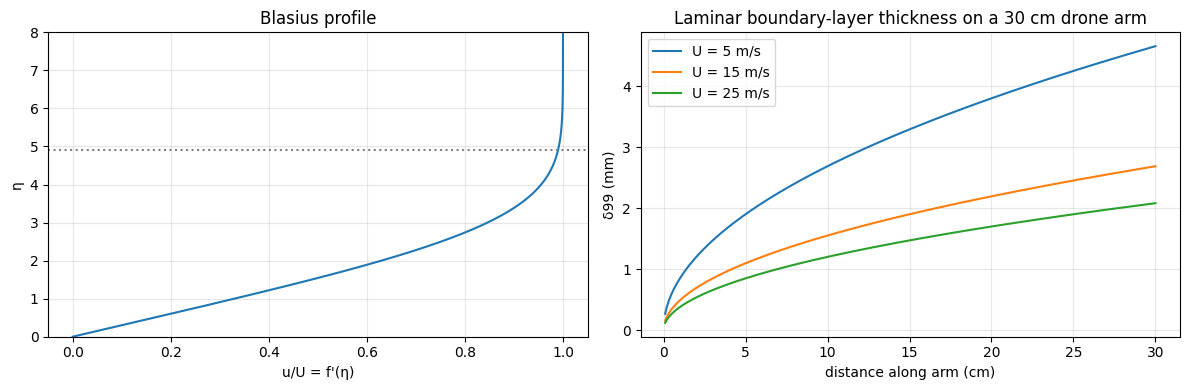

In [6]:
b = blasius()
print(f"f''(0)  = {b['fpp0']:.6f}   (textbook 0.332057)")
print(f"δ99 η   = {b['delta99']:.4f}     (textbook 4.91)")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(b["fp"], b["eta"]); axes[0].axhline(b["delta99"], color="0.5", ls=":")
axes[0].set(xlabel="u/U = f'(η)", ylabel="η", title="Blasius profile", ylim=(0, 8)); axes[0].grid(alpha=0.3)

xs = np.linspace(1e-3, 0.3, 300)
for U in (5, 15, 25):
    axes[1].plot(100*xs, 1000*b["delta99"]*xs/np.sqrt(reynolds(U, xs)), label=f"U = {U} m/s")
axes[1].set(xlabel="distance along arm (cm)", ylabel="δ99 (mm)",
            title="Laminar boundary-layer thickness on a 30 cm drone arm")
axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

Even at 30 cm the boundary layer is only a few millimeters thick. Outside it
the flow behaves as if $\mu = 0$. That justifies the inviscid control-volume
argument used in Part 4.

# Part 4: Rotor power from momentum theory

Draw a control volume around a hovering rotor's slipstream. Outside the thin
blade boundary layers, the integral form of Navier–Stokes with $\mu\to0$ gives:

- **mass:** $\dot m = \rho A v_i$, where $v_i$ is the induced velocity at the disk
- **momentum:** $T = \dot m\,w$, where $w$ is the far-wake velocity
- **energy:** $P = \tfrac12\dot m w^2$, and also $P = T v_i$

SymPy solves these:

In [7]:
d = actuator_disk_derivation()
for k, v in d.items():
    display(Math(f"{k} = " + sp.latex(v)))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

$w = 2v_i$: the wake ends up twice as fast as the flow through the disk. Ideal
power is $P = T^{3/2}/\sqrt{2\rho A}$, so **big, slow rotors are efficient**.
Doubling the rotor diameter at the same weight halves the power. Real rotors
reach a *figure of merit* FM ≈ 0.6–0.75 of that ideal.

**Forward flight.** With airspeed $V$, the rotor moves more air per second, so
less induced velocity is needed. Glauert's relation is
$v_i = v_h^2/\sqrt{V^2+v_i^2}$. Add parasite drag $\tfrac12\rho C_DA\,V^3$ and
the power curve has a **bucket**: a speed where the drone flies most cheaply.

hover power: 465 W


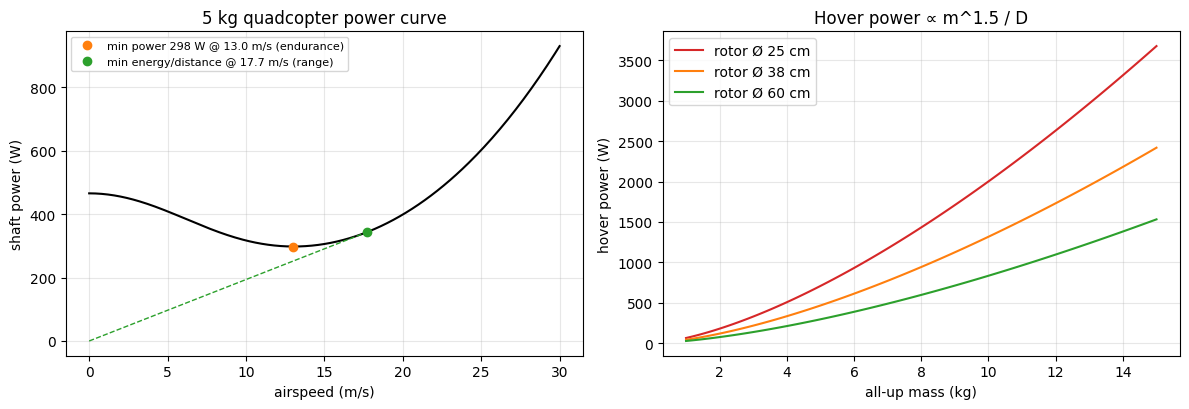

In [8]:
MASS, DIAM = 5.0, 0.38        # 5 kg loaded quad, 15-inch props (assumed)
print(f"hover power: {hover_power(MASS, DIAM):.0f} W")

V = np.linspace(0, 30, 301)
P = np.array([forward_flight_power(v, MASS, DIAM) for v in V])
k = np.argmin(P); kr = np.argmin(P / np.maximum(V, 1e-9))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].plot(V, P, "k")
axes[0].plot(V[k], P[k], "o", color="C1", label=f"min power {P[k]:.0f} W @ {V[k]:.1f} m/s (endurance)")
axes[0].plot([0, V[kr]], [0, P[kr]], "C2--", lw=1)
axes[0].plot(V[kr], P[kr], "o", color="C2", label=f"min energy/distance @ {V[kr]:.1f} m/s (range)")
axes[0].set(xlabel="airspeed (m/s)", ylabel="shaft power (W)", title=f"{MASS:.0f} kg quadcopter power curve")
axes[0].legend(fontsize=8); axes[0].grid(alpha=0.3)

m = np.linspace(1, 15, 100)
for D_, col in ((0.25, "C3"), (0.38, "C1"), (0.6, "C2")):
    axes[1].plot(m, [hover_power(mm, D_) for mm in m], col, label=f"rotor Ø {100*D_:.0f} cm")
axes[1].set(xlabel="all-up mass (kg)", ylabel="hover power (W)", title="Hover power ∝ m^1.5 / D")
axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

The tangent line from the origin picks out the **best-range speed**. That's the
speed minimizing $P/V$, i.e. energy per meter, and it's faster than the
minimum-power speed. A delivery drone should cruise near it.

# Part 5: Drone vs. robot vs. car, energy per mile

Each trip's energy is cruise power × time, plus fixed overhead. For the drone,
the overhead is about 60 s of hover for takeoff, lowering the package, and
landing. Robot rolling power is $C_{rr} m g v/\eta$. The EV figure is an assumed
round 250 Wh/mi.

In [9]:
Vbest = V[kr]
drone_cruise = forward_flight_power(Vbest, MASS, DIAM)
robot_power = 0.03 * 30 * 9.81 * 1.56 / 0.7
rows = [
    ("drone (cruise + 60 s hover)", energy_per_mile_wh(drone_cruise, Vbest, 60, hover_power(MASS, DIAM)), Vbest),
    ("sidewalk robot",               energy_per_mile_wh(robot_power, 1.56),                                  1.56),
    ("EV car (assumed 250 Wh/mi)",  250.0,                                                                  11.2),
]
for name, e, v in rows:
    print(f"{name:30s} {e:7.1f} Wh/mile   at {v/0.44704:5.1f} mph   ({1609.344/v/60:5.1f} min/mile)")

drone (cruise + 60 s hover)       16.4 Wh/mile   at  39.6 mph   (  1.5 min/mile)
sidewalk robot                     5.6 Wh/mile   at   3.5 mph   ( 17.2 min/mile)
EV car (assumed 250 Wh/mi)       250.0 Wh/mile   at  25.1 mph   (  2.4 min/mile)


For a 1-mile delivery, **the drone uses about 16 Wh and the robot about 6 Wh.
Both are 15–45× less than the EV**, which spends most of its energy moving
1,500 kg of car to carry 2 kg of food. Per mile, the drone uses about 3× the
robot's energy but is more than 10× faster. The drone gets speed close to the car's
at energy close to the robot's. What the drone pays in is noise, weather limits
(wind gusts can rival its 15 m/s airspeed), regulation, and the 60 s of
hovering, which is the most expensive part of its trip per second.

# Part 6: Auditing an "AI" flow prediction

Neural surrogates of CFD are everywhere: FNOs, PINNs, the FNO elsewhere in this
repo. They usually get validated by **data error** alone. Here's the problem
with that.

**Experiment.** Fit a degree-5 polynomial surrogate (168 coefficients, a linear
"network") to 400 samples of the Taylor–Green vortex. Then evaluate on held-out
points:

- the **data error** $\|u_\text{pred} - u_\text{true}\|$
- the **physics residuals**: continuity and momentum, computed from the
  surrogate's own derivatives

**A physics-informed fit.** Continuity $u_x + v_y = 0$ is *linear* in the
coefficients. Adding $\sqrt{\lambda}\,(u_x+v_y)=0$ rows at collocation points
therefore keeps the fit a single least-squares solve. It's a PINN without
gradient descent. Momentum is *nonlinear* ($u\,u_x$), so it can't be added this
way, and that's exactly where real PINNs need iterative training.

In [10]:
print(f"{'fit':28s} {'data RMSE':>10s} {'continuity':>11s} {'momentum':>10s}")
for label, kw in (("data only", dict()),
                  ("data + continuity (λ=1)", dict(lam_div=1.0)),
                  ("data + continuity (λ=100)", dict(lam_div=100.0)),
                  ("data only, 2% noise", dict(noise=0.02)),
                  ("noise + continuity (λ=100)", dict(noise=0.02, lam_div=100.0))):
    r = fit_surrogate(**kw)
    print(f"{label:28s} {r['data_rmse']:10.4f} {r['continuity_rms']:11.2e} {r['momentum_rms']:10.4f}")
print("\nscale of the terms: |u_t| ~ 2ν|u| ~ 0.2, |∇p/ρ| ~ 0.5")

fit                           data RMSE  continuity   momentum
data only                        0.0041    8.10e-03     0.0327


data + continuity (λ=1)          0.0039    2.53e-04     0.0348
data + continuity (λ=100)        0.0039    3.06e-06     0.0348
data only, 2% noise              0.0111    3.26e-02     0.0553
noise + continuity (λ=100)       0.0089    2.68e-05     0.0501

scale of the terms: |u_t| ~ 2ν|u| ~ 0.2, |∇p/ρ| ~ 0.5


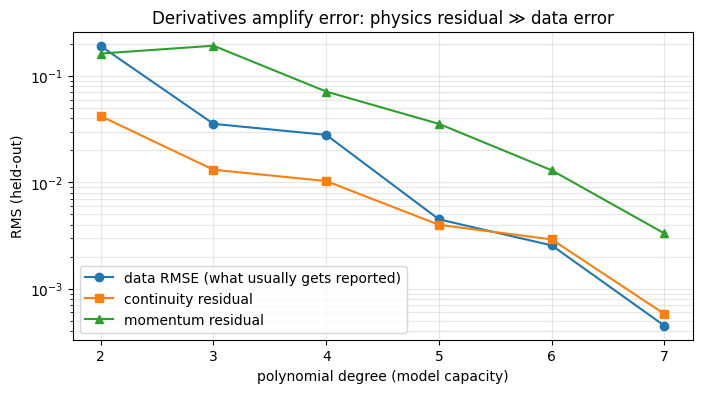

In [11]:
degs = [2, 3, 4, 5, 6, 7]
res = [fit_surrogate(deg=d_, n_data=600) for d_ in degs]
fig, ax = plt.subplots(figsize=(8, 4))
ax.semilogy(degs, [r["data_rmse"] for r in res], "o-", label="data RMSE (what usually gets reported)")
ax.semilogy(degs, [r["continuity_rms"] for r in res], "s-", label="continuity residual")
ax.semilogy(degs, [r["momentum_rms"] for r in res], "^-", label="momentum residual")
ax.set(xlabel="polynomial degree (model capacity)", ylabel="RMS (held-out)",
       title="Derivatives amplify error: physics residual ≫ data error")
ax.legend(); ax.grid(alpha=0.3, which="both"); plt.show()

**Takeaways for reading AI-for-physics results:**

1. **0.4% data error can still mean a 10% momentum residual.** The residual is
   built from first and second derivatives, and differentiation amplifies
   high-frequency error. A model can match the data closely and still violate
   Newton's second law.
2. **Constraints that are linear in the parameters are free.** The continuity
   penalty drives the divergence down 1000× *without* hurting the data fit,
   because the true field satisfies both.
3. **Noise makes it worse.** With 2% noise, a flexible model fits the noise,
   and its derivatives blow up.
4. **When you read a paper's results, ask for the residual, not just the
   error.** This is the same idea as the Kramers–Kronig certificate in this
   repo: checking that an output obeys a physical law is a separate test from
   checking that it matches the data.

# Part 7: Applied EM. Dispersion is diffusion with an imaginary viscosity.

Stokes' first problem reduced Navier–Stokes to $u_t = \nu u_{yy}$. A pulse in a
dispersive fiber (Agrawal, *Nonlinear Fiber Optics*) obeys

$$i\,\partial_z A = \frac{\beta_2}{2}\,\partial_T^2 A \quad\Longleftrightarrow\quad \partial_z A = \Big(-\frac{i\beta_2}{2}\Big)\partial_T^2 A$$

This is the diffusion equation with $z$ in place of $t$ and the **imaginary**
diffusivity $-i\beta_2/2$ in place of $\nu$. Their Gaussian solutions are the
same function under

$$y \to T,\qquad \sigma_0 \to T_0,\qquad 2\nu t \;\to\; -i\beta_2 z$$

SymPy checks all three claims: both PDEs are satisfied, and the mapping gives
exactly the fiber solution.

In [12]:
r_diff, r_disp, same = check_analogy()
print("diffusion PDE residual :", r_diff)
print("dispersion PDE residual:", r_disp)
print("mapped(diffusion) - fiber solution:", same)
display(Math(r"u = " + sp.latex(diffusion_gaussian())))
display(Math(r"A = " + sp.latex(dispersed_pulse()[0])))

diffusion PDE residual : 0
dispersion PDE residual: 0
mapped(diffusion) - fiber solution: 0


<IPython.core.display.Math object>

<IPython.core.display.Math object>

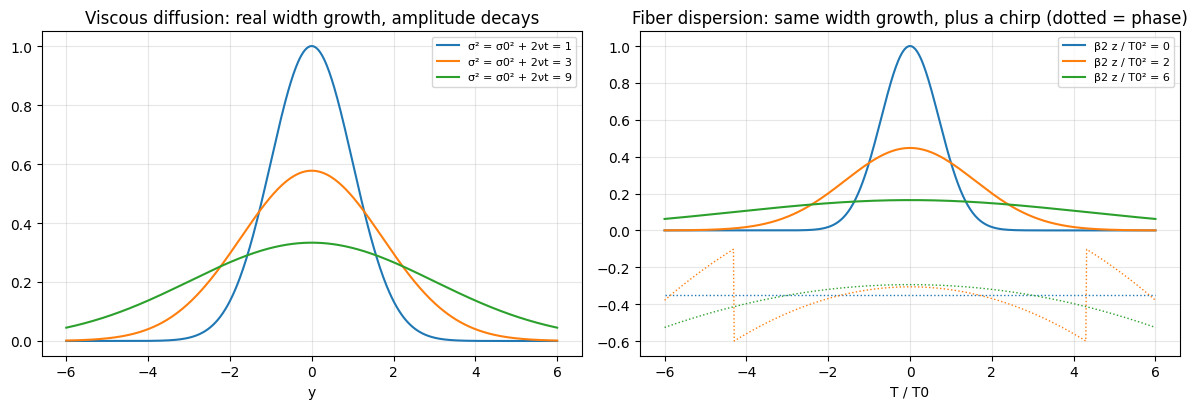

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
yy = np.linspace(-6, 6, 600)
for s2, col in ((1, "C0"), (3, "C1"), (9, "C2")):
    axes[0].plot(yy, np.exp(-yy**2/(2*s2))/np.sqrt(s2), col, label=f"σ² = σ0² + 2νt = {s2}")
axes[0].set(title="Viscous diffusion: real width growth, amplitude decays", xlabel="y")
axes[0].legend(fontsize=8); axes[0].grid(alpha=0.3)

T = np.linspace(-6, 6, 600)
for b2z, col in ((0, "C0"), (2, "C1"), (6, "C2")):
    q = 1 - 1j*b2z
    A = np.exp(-T**2/(2*q))/np.sqrt(q)
    axes[1].plot(T, np.abs(A)**2, col, label=f"β2 z / T0² = {b2z}")
    axes[1].plot(T, np.angle(A)/np.pi/4 - 0.35, col, ls=":", lw=1)
axes[1].set(title="Fiber dispersion: same width growth, plus a chirp (dotted = phase)", xlabel="T / T0")
axes[1].legend(fontsize=8); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

**In the Fourier domain the analogy is a single line.** Each Fourier component is
multiplied by a transfer function:

| | transfer function | effect |
|---|---|---|
| viscosity | $e^{-\nu k^2 t}$ | real, so high $k$ is **damped**. Information is lost. |
| fiber dispersion | $e^{\,i\beta_2\omega^2 z/2}$ | pure phase, so high $\omega$ is **delayed**. Nothing is lost. |

The second row is the photonic time-stretch transfer function
$H(f) = e^{\,j\pi D f^2}$ that Prof. Jalali's lab built STEAM on, and that this
repo's phase retrieval inverts. Because $|H| = 1$, dispersion is *invertible*
while viscous diffusion is not. You can un-stretch a pulse, but you can't
un-mix cream from coffee. That's also why recovering phase from two intensity
measurements $I_1, I_2$ works at all: the quadratic phase moves the information
around without destroying it.

# Summary

| Part | result |
|---|---|
| NS | after scaling, only $Re$ remains. Drone flows have $Re\sim10^4$–$10^5$, so viscosity matters only near surfaces |
| exact solutions | 4 of them, each verified by substitution with zero residual |
| Blasius | $f''(0)=0.33206$, $\delta_{99}=4.91\,x/\sqrt{Re_x}$, a few mm on a drone arm |
| rotor | $P=T^{3/2}/\sqrt{2\rho A}$, so big slow rotors win. The forward-flight power curve has a bucket |
| energy | drone ≈ 16 Wh, robot ≈ 6 Wh per mile, both 15–45× less than an EV |
| AI audit | report physics residuals, not just data error. Linear constraints are free |
| EM | fiber dispersion = diffusion with $\nu \to -i\beta_2/2$. Unitary, so invertible |

## Exercises

1. Verify **Stokes' second problem** (oscillating plate) $u = U e^{-ky}\cos(\omega t - ky)$,
   $k=\sqrt{\omega/2\nu}$, with `ns_residuals`.
2. Is $u = \sin x\cos y\,e^{-\nu t}$ (with the Taylor–Green $v$, $p$) a solution?
   Read the residual SymPy gives you and explain the factor of 2.
3. Redo Part 4 for a coaxial octocopter (8 rotors of 0.3 m). What happens to hover power?
4. In Part 6, add the *linearized* momentum equation (drop $u\,u_x$) as a
   penalty. Does the full nonlinear residual drop?
5. Using the Fourier table, explain why a Gerchberg–Saxton algorithm can recover
   phase after dispersion but would fail after diffusion.